## Predictive Maintenance - Data Exploration

In [64]:
#Load the predictive maintenance dateset
import pandas as pd
df = pd.read_csv("../data/ai4i2020.csv")
# Display the first 5 observations
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [65]:
# Check the dataset dimensions
df.shape

(10000, 14)

In [66]:
# Display the dataset column names
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='str')

In [67]:
# Inspect dataset structure and data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

We could observe that the 14 columns contain 10000 non-null values, which indicates that the dataset has no missing values.

In [68]:
# Display descriptive statistics for numerical features
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


**Observations:**
. The average air temperature is approximately 300K, with a standard deviation std = 2K --> The air temperatures are relatively close to the mean of 300K, so low variability
. Only 3.39% of the observations correspond to machine failures (since the it's a binary classification and the mean of the feature machine failure = 0.033900)
--> We can conclude that the dataset is highly imbalanced: more non-failure observations than failure observations

In [69]:
# Check for missing values (even though we already concluded earlier that there is no missing values)
sum_missing_values = df.isnull().sum()    #True(1): missing value, False(1): present value
if sum_missing_values.sum()> 0:
    print("There are some values missing")
else:
    print("No missing values")


No missing values


In [70]:
# Count observations with and without machine failure
df["Machine failure"].value_counts()
#Display the proportion of failures and non-failures
df["Machine failure"].value_counts(normalize=True) * 100

Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64

## Exploratory Data Analysis (EDA) — Visualizations

In this section, we visualize the dataset to explore feature distributions and relationships with machine failures.

In [116]:
import matplotlib.pyplot as plt

Machine failure
0    9661
1     339
Name: count, dtype: int64


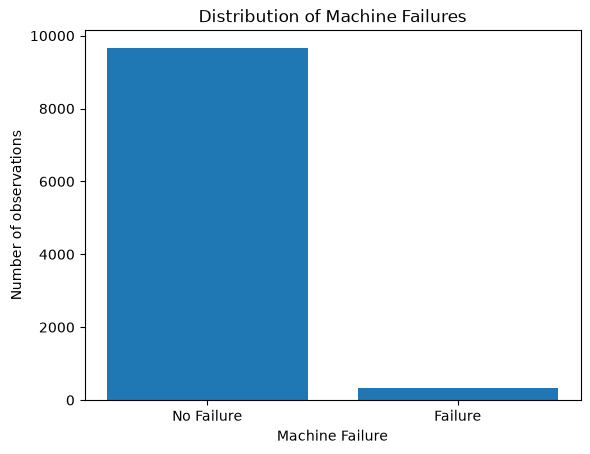

In [117]:
# Visualize the distribution of machine failures
failure_counts = df["Machine failure"].value_counts()

print(failure_counts)
plt.bar(failure_counts.index, failure_counts.values)
plt.title("Distribution of Machine Failures")
plt.xlabel("Machine Failure")
plt.ylabel("Number of observations")
plt.xticks([0,1],["No Failure", "Failure"])
plt.show()

**Observation:** The dataset is highly imbalanced: 96.61% of observations correspond to normal machine operation, while only 3.39% represent machine failures.
--> This class imbalance must be considered when evaluating the ML models because accuracy alone could be misleading.

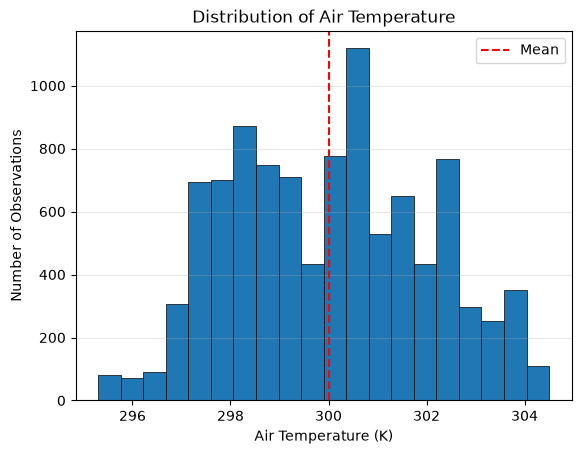

In [118]:
# Visualize the distribution of air temperature
plt.hist(df["Air temperature [K]"],bins=20, edgecolor="black", linewidth=0.5)   #bins: number of intervals used to group the values

plt.title("Distribution of Air Temperature")
plt.xlabel("Air Temperature (K)")
plt.ylabel("Number of Observations")

# Mark the mean air temperature
plt.axvline(df["Air temperature [K]"].mean(), color="red", linestyle="--", label="Mean")

plt.grid(axis="y", alpha=0.3)   # Add a light horizontal grid to improve readability

plt.legend()
plt.show()

**Observation:** Air temperatures are centered around 300 K, with a standard deviation of approximately 2 K. The distribution shows a noticeable peak around 300.5 K and several smaller peaks.

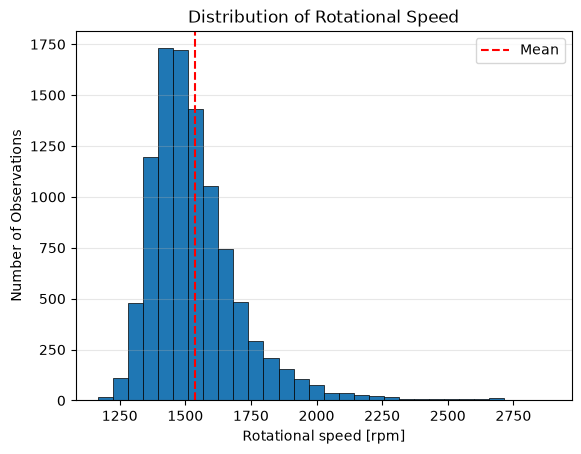

In [119]:
# Visualize the distribution of rotational speed
plt.hist(df["Rotational speed [rpm]"],bins=30, edgecolor="black", linewidth=0.5)   #bins: number of intervals used to group the values

plt.title("Distribution of Rotational Speed")
plt.xlabel("Rotational speed [rpm]")
plt.ylabel("Number of Observations")

# Mark the mean rotational speed
plt.axvline(df["Rotational speed [rpm]"].mean(), color="red", linestyle="--", label="Mean")

plt.grid(axis="y", alpha=0.3)

plt.legend()
plt.show()

**Observation:** Rotational speed is mainly concentrated between 1,300 and 1,700 rpm, with a mean of approximately 1,539 rpm. The distribution is right-skewed, showing a long tail toward higher speeds and a few potentially extreme values.

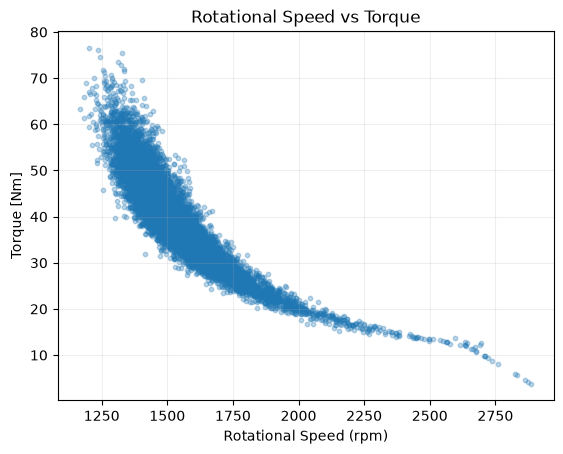

In [120]:
# Explore the relationship between rotational speed and torque
plt.scatter(df["Rotational speed [rpm]"], df["Torque [Nm]"], alpha=0.3, s=10)
# Smaller points (s=10) improve visibility, while transparency (alpha=0.3) highlights dense areas.
plt.title("Rotational Speed vs Torque")
plt.xlabel("Rotational Speed (rpm)")
plt.ylabel("Torque [Nm]")
plt.grid(alpha=0.2)
plt.show()

**Observation:** The scatter plot shows a **strong negative, non-linear relationship between rotational speed and torque** : as speed increases, torque decreases, steeply at first and then more gradually. Torque varies widely at low speeds but shows less variation at high speeds.

In [121]:
# Separate tool wear values by machine failure status
wear_no_failure = df[df["Machine failure"] == 0]  # Filter observations without machine failure
wear_no_failure = wear_no_failure["Tool wear [min]"] # Select tool wear values

wear_failure = df[df["Machine failure"] == 1] ["Tool wear [min]"]

# Check the number of observations in each group
print("No Failure:", len(wear_no_failure))
print("Failure:", len(wear_failure))

No Failure: 9661
Failure: 339


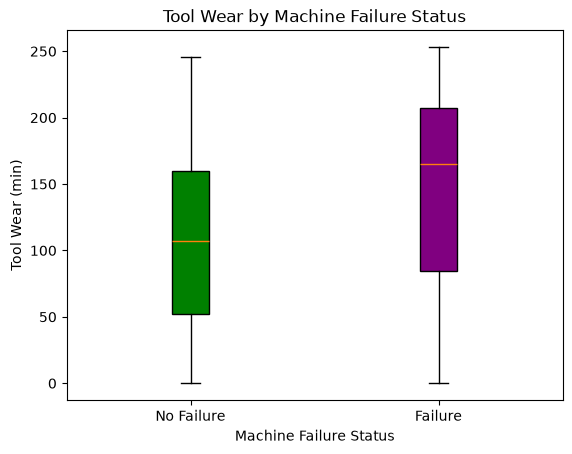

In [122]:
# Compare tool wear distributions by failure status
boxes = plt.boxplot([wear_no_failure,wear_failure],patch_artist=True)
# Set different colors for each failure status
boxes["boxes"][0].set_facecolor("green")  # No Failure
boxes["boxes"][1].set_facecolor("purple")   # Failure

plt.title("Tool Wear by Machine Failure Status")
plt.xlabel("Machine Failure Status")
plt.ylabel("Tool Wear (min)")

plt.xticks([1,2],["No Failure", "Failure"])
plt.show()


**Observation:** Machine failures are associated with higher tool wear, with a median of approximately 165 minutes for failure cases compared to 107 minutes for non-failure cases. However, the distributions overlap considerably, suggesting that tool wear alone is not sufficient to distinguish between failures and non-failures.

## Key Findings
**1. Class Imbalance:** The dataset is highly imbalanced, with only 3.39% of observations representing machine failures. Therefore, accuracy alone may be misleading when evaluating our models.

**2. Air Temperature:** Air temperatures are centered around 300 K, with a standard deviation of approximately 2 K, indicating relatively low variability.

**3. Rotational Speed:** Rotational speed is mainly concentrated between 1,300 and 1,700 rpm. Its distribution is right-skewed, with a long tail toward higher speeds.

**4. Rotational Speed vs Torque:** A strong negative, non-linear relationship is observed between rotational speed and torque. As rotational speed increases, torque generally decreases.

**5. Tool Wear vs Machine Failure:** Observations with machine failures tend to have higher tool wear, with a median of approximately 165 minutes compared to 107 minutes for non-failure observations. However, the distributions overlap considerably, indicating that tool wear alone cannot reliably distinguish failures from non-failures.
